# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [3]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [8]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/Lab_11_QnA_Dataset_Download.csv'

## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [10]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [11]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

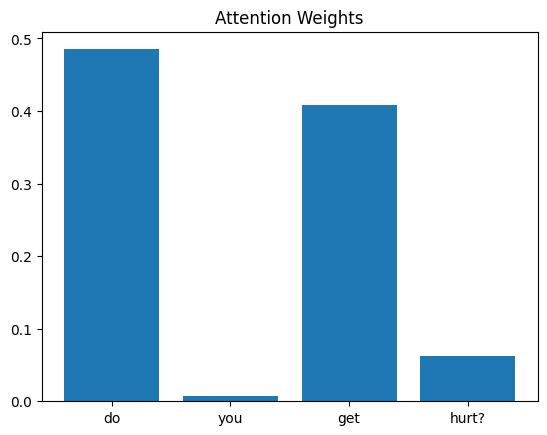

In [12]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [13]:
df = pd.read_excel("/content/Lab_11_QnA_Dataset.xlsx")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [14]:
# Display questions from the dataset
for i in range(20):
    print(i, "-", df.iloc[i]["question"])

0 - Do you get hurt?
1 - Do you have fingers?
2 - Do you ever breathe
3 - Do you masticate?
4 - Can you throw up?
5 - Do you get tired?
6 - Can you crawl?
7 - Can you cry?
8 - Do you dream
9 - Do you ever pee?
10 - Do you ever get hurt?
11 - Can you breathe
12 - can you masticate?
13 - Can you burp?
14 - Are you old?
15 - Are we the same age?
16 - How long have you been alive?
17 - Are you a teenager?
18 - What's your birthday?
19 - Which of us is younger?


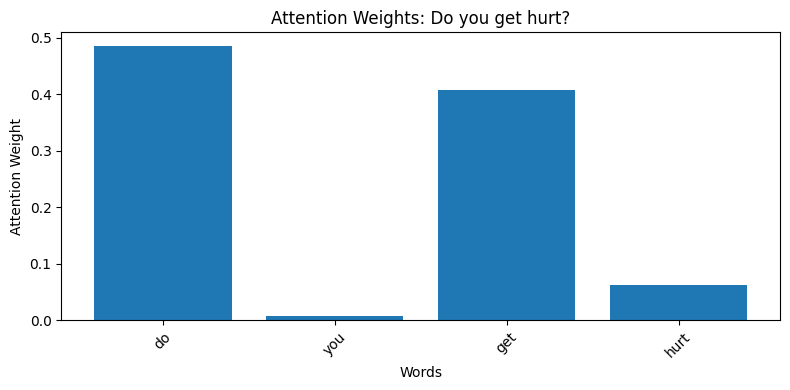

Question: Do you get hurt?
Highest Attention Word: do
Attention Weight: 0.485117
----------------------------------------


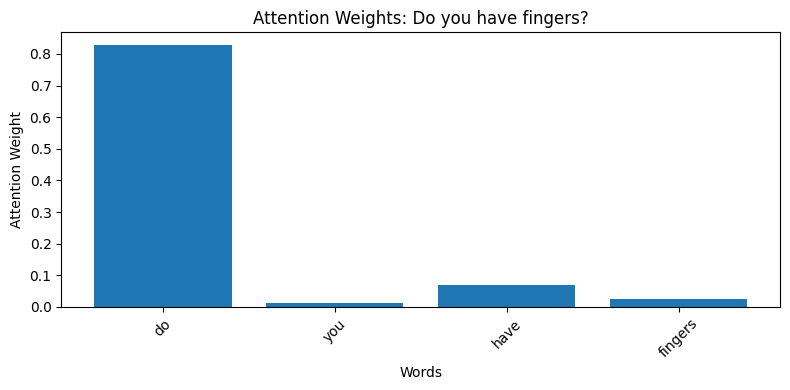

Question: Do you have fingers?
Highest Attention Word: do
Attention Weight: 0.8269948
----------------------------------------


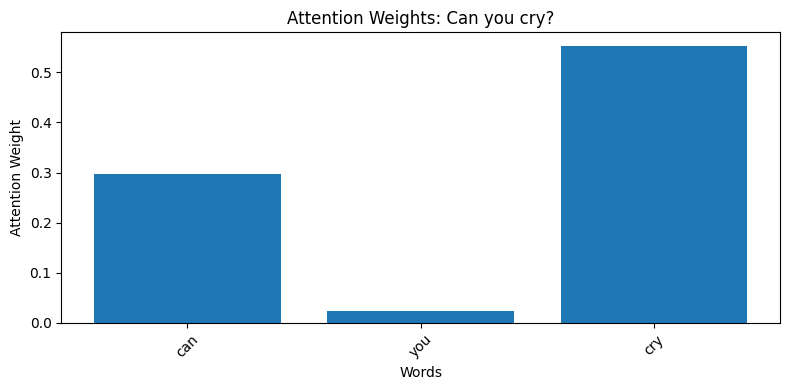

Question: Can you cry?
Highest Attention Word: cry
Attention Weight: 0.55243593
----------------------------------------


In [15]:
import matplotlib.pyplot as plt

model.eval()

selected_indices = [0, 1, 7]

for idx in selected_indices:

    question = df.iloc[idx]["question"]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    weights = weights[0].cpu().numpy()
    token_ids = X[idx].cpu().tolist()

    valid_positions = [
        i for i, token_id in enumerate(token_ids) if token_id != 0
    ]

    words = [
        tokenizer.index_word.get(token_ids[i], "<UNK>")
        for i in valid_positions
    ]

    word_weights = [weights[i] for i in valid_positions]

    plt.figure(figsize=(8, 4))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    max_index = word_weights.index(max(word_weights))

    print("Question:", question)
    print("Highest Attention Word:", words[max_index])
    print("Attention Weight:", word_weights[max_index])
    print("-" * 40)

The results show that the model focuses on different words depending on the question. For the first two questions, the word “do” received the highest attention weights (0.4851 and 0.8270). For the third question, the word “cry” received the highest attention weight (0.5524).

The word “cry” is directly related to the meaning of the question, while “do” is a common auxiliary verb. This suggests that attention does not always focus on the most meaningful word. However, it helps the model assign different importance levels to words when processing questions.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

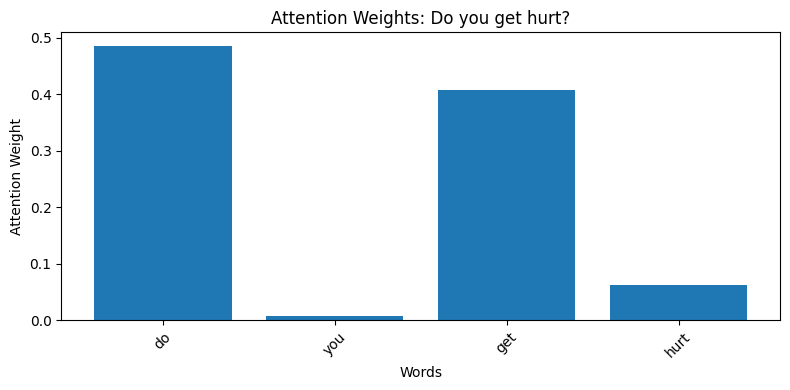

Question: Do you get hurt?
Highest Attention Word: do
Attention Weight: 0.485117
----------------------------------------


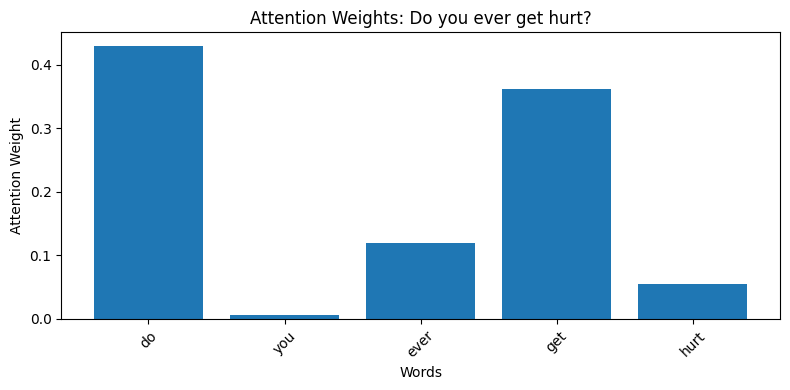

Question: Do you ever get hurt?
Highest Attention Word: do
Attention Weight: 0.4295142
----------------------------------------


In [16]:
selected_indices = [0, 10]

model.eval()

for idx in selected_indices:

    question = df.iloc[idx]["question"]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    weights = weights[0].cpu().numpy()
    token_ids = X[idx].cpu().tolist()

    valid_positions = [
        i for i, token_id in enumerate(token_ids) if token_id != 0
    ]

    words = [
        tokenizer.index_word.get(token_ids[i], "<UNK>")
        for i in valid_positions
    ]

    word_weights = [weights[i] for i in valid_positions]

    plt.figure(figsize=(8, 4))
    plt.bar(words, word_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    max_index = word_weights.index(max(word_weights))

    print("Question:", question)
    print("Highest Attention Word:", words[max_index])
    print("Attention Weight:", word_weights[max_index])
    print("-" * 40)

The model focuses on similar words when processing questions with similar meanings but different wording. In both questions, “Do you get hurt?” and “Do you ever get hurt?”, the word “do” received the highest attention weight (0.4851 and 0.4295).

Although the second question contains the additional word “ever”, the model still focuses most on “do”. This suggests that the attention mechanism can identify similar patterns in questions with similar meanings, even when their wording is slightly different.